# 5.5 Connecting Image and Text Representations

**Module 5 · Note 5**

So far in this module, images and text have lived in separate worlds. In Note 5.2, a CNN turned images into vectors. In Note 5.3, an embedding layer turned words into vectors. Both are representations, but they are completely unrelated: a CNN's vector for a photo of a bag and an embedding's vector for the word "bag" have nothing to do with each other, and may not even be the same length.

Yet some of the most impressive AI systems work *across* images and text. You can type "a red sneaker on a white background" into a photo library and get matching pictures, without anyone having labelled those photos. Image generators turn sentences into pictures. Assistants answer questions about images you upload. All of these depend on one idea: **putting images and text into the same representation space**, so that a picture and a sentence describing it end up as nearby vectors.

In this note we will build a small version of that idea from scratch. We will train an image encoder and a text encoder *together*, with a training method called **contrastive learning**, so that matching images and captions point the same way. Then we will use the result to classify images using only text descriptions, and to search images with a sentence. Finally, we will connect our toy model to **CLIP**, the well-known model that made this approach famous, and that you will use for real in Module 7.

**Key question:** *How can images and text be represented in a way that lets us compare them directly?*

**By the end of this note you will be able to:**
- explain what a modality is and why separate encoders produce incompatible representations;
- explain how projection into a shared space makes images and text comparable;
- explain contrastive learning and compute a contrastive loss by hand;
- train a small image–text model and use it for text-based classification and search;
- explain what CLIP does, how our toy model resembles it, and where it falls short.

**Before you start:** read Notes 5.2 and 5.3. You will need CNNs, embeddings, cosine similarity and cross-entropy loss.

### Setup

Run this cell first. We use Fashion-MNIST again: the same 50,000 training and 10,000 validation images as in Note 5.2.

In [1]:
import os, gzip, urllib.request
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(0)
np.random.seed(0)
print("PyTorch", torch.__version__)

PyTorch 2.14.1+cu130


## 1. What Does It Mean to Represent Different Modalities?

A **modality** is a *type* of data, defined by how it is recorded: images, text, audio, video, sensor readings. Each modality has its own structure. Images are 2D grids of pixels where neighbours matter; text is a sequence of discrete symbols where order matters. That is why we used different encoders for them: a CNN for images, an embedding layer for text.

Each encoder produces a vector, but there is no reason for the vectors from two separately trained encoders to be comparable. Imagine two people describing the same building, one in French using metres and one in Japanese using feet. Each description is accurate, but you cannot compare them number by number until you agree on a shared language and shared units. A **shared representation space** is that agreement: a single space in which an image of a bag and the text "a photo of a bag" land in the same place.

> 🖼 *IMAGE 5.5.1 — Two Separate Spaces vs. One Shared Space.* Two panels on a white background. Left panel titled "Separate encoders, separate spaces": two unconnected circles. The left circle, labelled "image space", contains small greyscale thumbnails of a bag, a sneaker and a dress scattered around. The right circle, labelled "text space", contains the phrases "a bag", "a sneaker", "a dress" scattered in different positions, with a large red "≠" between the circles and a note "no way to compare". Right panel titled "Shared space": one large circle with three clusters; each cluster pairs a thumbnail with its phrase side by side (bag thumbnail next to "a bag", sneaker next to "a sneaker", dress next to "a dress"), with short green lines linking each pair. Takeaway: a shared space puts matching images and text close together, so they can be compared directly.

We start by loading the images. We will create the text ourselves in Section 2.

In [2]:
DATA_DIR = "data/fashion"
BASE_URL = "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/"
FILES = ["train-images-idx3-ubyte.gz", "train-labels-idx1-ubyte.gz"]
os.makedirs(DATA_DIR, exist_ok=True)
for f in FILES:
    if not os.path.exists(os.path.join(DATA_DIR, f)):
        urllib.request.urlretrieve(BASE_URL + f, os.path.join(DATA_DIR, f))
def read_idx(f, offset):
    with gzip.open(os.path.join(DATA_DIR, f)) as fh:
        return np.frombuffer(fh.read(), dtype=np.uint8, offset=offset)
X_all = torch.tensor(read_idx(FILES[0], 16).reshape(-1, 1, 28, 28), dtype=torch.float32) / 255.0
y_all = torch.tensor(read_idx(FILES[1], 8).astype(np.int64))
X_train, y_train = X_all[:50000], y_all[:50000]
X_val, y_val = X_all[50000:], y_all[50000:]
NAMES = ["t-shirt", "trouser", "pullover", "dress", "coat", "sandal", "shirt", "sneaker", "bag", "ankle boot"]
print("train images:", tuple(X_train.shape), "| validation images:", tuple(X_val.shape))

train images: (50000, 1, 28, 28) | validation images: (10000, 1, 28, 28)


## 2. Mapping Different Modalities into a Shared Representation Space

### 2.1 Our image–text dataset

A shared space is learned from **pairs**: an image together with text that describes it. Real systems learn from enormous collections of images and captions gathered from the internet. We will make simple captions ourselves from the class names, using four sentence patterns called **templates**, so that each class can be described in several different ways.

In [3]:
TEMPLATES = ["a photo of a {}", "a picture of a {}", "an image showing a {}", "a {} on a plain background"]
captions = [[t.format(n) for t in TEMPLATES] for n in NAMES]      # captions[class][template]
words = sorted({w for caps in captions for c in caps for w in c.split()})
stoi = {w: i for i, w in enumerate(words)}
print("captions per class:", len(TEMPLATES), "| total distinct captions:", len(NAMES) * len(TEMPLATES))
print("vocabulary size:", len(words))
print(captions[7])

captions per class: 4 | total distinct captions: 40
vocabulary size: 21
['a photo of a sneaker', 'a picture of a sneaker', 'an image showing a sneaker', 'a sneaker on a plain background']


Each class gets 4 captions, which makes 40 distinct captions in total, built from a vocabulary of only 21 words. The four captions for class 7 are shown: "a photo of a sneaker", "a picture of a sneaker", "an image showing a sneaker" and "a sneaker on a plain background". During training, every image will be paired with one of its class's captions, chosen at random.

### 2.2 Two encoders and two projections

The recipe for a shared space has three parts:

1. An **image encoder** that turns an image into a vector. We use the same small CNN as in Note 5.2.
2. A **text encoder** that turns a caption into a vector. We use the bag-of-embeddings idea from Note 5.3: look up each word's embedding and average them.
3. A **projection** at the end of each encoder: a linear layer that maps the encoder's output into the shared space. Both projections output vectors of the **same length**, 32 numbers, and we normalise each vector to length 1, so that their dot product equals their cosine similarity.

In [4]:
class ImageEncoder(nn.Module):
    def __init__(self, dim=32):
        super().__init__()
        self.cnn = nn.Sequential(nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                                 nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Flatten())
        self.proj = nn.Linear(32 * 7 * 7, dim)       # project 1,568 CNN features into the shared space
    def forward(self, x):
        return F.normalize(self.proj(self.cnn(x)), dim=-1)

class TextEncoder(nn.Module):
    def __init__(self, vocab_size, dim=32):
        super().__init__()
        self.emb = nn.EmbeddingBag(vocab_size, 32, mode="mean")   # average of word embeddings
        self.proj = nn.Linear(32, dim)                            # project into the shared space
    def forward(self, texts):
        ids = [torch.tensor([stoi[w] for w in t.split()]) for t in texts]
        offsets = torch.tensor([0] + [len(i) for i in ids[:-1]]).cumsum(0)
        return F.normalize(self.proj(self.emb(torch.cat(ids), offsets)), dim=-1)

torch.manual_seed(0)
img_enc, txt_enc = ImageEncoder(), TextEncoder(len(words))
with torch.no_grad():
    print("raw CNN features per image:", img_enc.cnn(X_val[:1]).shape[1])
    print("image vector:", tuple(img_enc(X_val[:2]).shape), "| text vector:", tuple(txt_enc(["a photo of a bag", "a photo of a coat"]).shape))
    print("length of each vector after normalising:", round(img_enc(X_val[:1]).norm().item(), 3))

raw CNN features per image: 1568
image vector: (2, 32) | text vector: (2, 32)
length of each vector after normalising: 1.0


The CNN on its own produces 1,568 numbers per image, while the text encoder's word embeddings have 32 numbers. Those two cannot be compared at all. After the projections, both produce vectors of shape `(batch, 32)`, and each has length 1.0. Now an image and a caption *can* be compared, with a single dot product.

But being comparable is not the same as being *meaningful*. Let's test the untrained encoders. For each validation image, we compute its similarity with the 10 descriptions "a photo of a t-shirt", "a photo of a trouser" and so on, and pick the most similar. If the space were meaningful, this would classify images correctly using only text.

In [5]:
def class_prompts(template="a photo of a {}"):
    return [template.format(n) for n in NAMES]

def zero_shot_accuracy(img_enc, txt_enc, X, y, template="a photo of a {}"):
    with torch.no_grad():
        T = txt_enc(class_prompts(template))         # (10, dim): one vector per class description
        I = img_enc(X)                               # (N, dim)
        pred = (I @ T.T).argmax(1)                   # pick the most similar description
    return (pred == y).float().mean().item(), pred

acc0, _ = zero_shot_accuracy(img_enc, txt_enc, X_val, y_val)
print(f"untrained encoders: matching validation images to class descriptions, accuracy {acc0:.3f}")

untrained encoders: matching validation images to class descriptions, accuracy 0.100


With untrained encoders, the accuracy is 0.100: exactly what random guessing among 10 classes would give. The two encoders produce vectors of the same size, but they have no reason to agree. We need to **train** them so that matching images and captions end up close together.

> **Key terms**
> - **Modality:** a type of data, such as images, text or audio.
> - **Shared representation space:** a single vector space in which data from different modalities can be compared directly.
> - **Projection:** a layer, usually linear, that maps an encoder's output into the shared space.
> - **Normalise (to unit length):** divide a vector by its length so that its length becomes 1; then dot product equals cosine similarity.

> **Check yourself 1.** Why do the image and text projections have to output vectors of the same length?

## 3. Contrastive Learning: The Core Intuition

How do we train two encoders so that matching pairs are close? We cannot simply tell the network "the correct vector for a bag is this one", because nobody knows what the right vectors are. What we *do* know is which image goes with which caption. **Contrastive learning** uses exactly that.

Take a batch of images, each with its own caption. Compute the similarity of **every image with every caption** in the batch. The training goal is:

- **pull together** each image and its own caption (the **positive pair**);
- **push apart** each image and all the other captions in the batch (the **negative pairs**).

Think of a seating chart at a wedding. You don't know the exact coordinates where each guest should sit, but you know who belongs with whom. Moving partners together and strangers apart, again and again, gradually produces a sensible arrangement of the whole room.

> 🖼 *IMAGE 5.5.2 — The Contrastive Similarity Matrix.* A 4×4 grid on a white background. Along the left edge, four small greyscale thumbnails labelled image 1 to 4 (a bag, a sneaker, a dress, a coat). Along the top, four caption boxes labelled caption 1 to 4 ("a photo of a bag", "a picture of a sneaker", "an image showing a dress", "a coat on a plain background"). The four diagonal cells are coloured bright green with an upward arrow and the label "pull together (positive pairs)". All twelve off-diagonal cells are coloured pale red with a downward arrow, labelled "push apart (negative pairs)". On the right, a bracket around one row labelled "row: which caption fits this image?"; on the bottom, a bracket around one column labelled "column: which image fits this caption?". Takeaway: contrastive learning makes the diagonal of the similarity matrix high and everything else low.

### 3.1 The contrastive loss, by hand

Here is the loss on a tiny made-up example with 4 images and 4 captions. `S[i, j]` is the similarity between image i and caption j, and the correct matches are on the diagonal.

We read the matrix **row by row**: each row asks "which of the 4 captions belongs to this image?". That is a 4-way classification problem, so we can use the ordinary **softmax and cross-entropy** loss from classification, with the correct answer being the diagonal entry. We then do the same **column by column** ("which image belongs to this caption?") and average the two. Before the softmax, the similarities are multiplied by a **scale**, here 10, which controls how sharply the softmax separates the scores. (In CLIP it is described as dividing by a **temperature**, which is the same thing.)

In [6]:
S = torch.tensor([[0.9, 0.1, 0.0, 0.2],
                  [0.2, 0.8, 0.1, 0.0],
                  [0.1, 0.3, 0.7, 0.1],
                  [0.0, 0.1, 0.2, 0.6]])      # S[i, j] = similarity of image i and caption j
scale = 10.0
targets = torch.arange(4)                     # image i belongs with caption i: the diagonal
probs_img_to_txt = torch.softmax(scale * S, dim=1)
print("each image's probability over the 4 captions:\n", probs_img_to_txt.round(decimals=3))
loss_i = F.cross_entropy(scale * S, targets)      # rows: image -> which caption?
loss_t = F.cross_entropy(scale * S.T, targets)    # columns: caption -> which image?
print(f"image->text loss {loss_i:.3f} | text->image loss {loss_t:.3f} | contrastive loss {(loss_i + loss_t) / 2:.3f}")

each image's probability over the 4 captions:
 tensor([[0.9990, 0.0000, 0.0000, 0.0010],
        [0.0020, 0.9960, 0.0010, 0.0000],
        [0.0020, 0.0180, 0.9770, 0.0020],
        [0.0020, 0.0070, 0.0180, 0.9730]])
image->text loss 0.014 | text->image loss 0.012 | contrastive loss 0.013


In this example, the diagonal entries are clearly the largest in each row, so after scaling and softmax, each image puts almost all its probability on its own caption: 0.999, 0.996, 0.977 and 0.973. The loss is correspondingly small: 0.014 for the rows, 0.012 for the columns, and 0.013 on average. If an off-diagonal similarity were higher than the diagonal one, the probability on the correct caption would drop and the loss would rise sharply. That is the signal that drives learning.

### 3.2 Training our toy model

The `contrastive_loss` function below does exactly this for a whole batch. In every training step, we draw 128 random training images, give each one a random caption from its own class, embed both, and minimise the contrastive loss. We train for 400 steps.

The training function also records a **floor** for the loss, which needs explaining. Each batch contains about 12.8 images of each class, and many of their captions are identical or nearly so. Our model is *supposed* to map all bag images to the same place, so it cannot tell which of the roughly 13 bag images in the batch belongs to a particular bag caption. The best it can do is spread the probability evenly among them, and that gives a loss of about the logarithm of their number. These same-class "negatives" are called **false negatives**: pairs that the loss treats as wrong, even though they are a perfectly good match.

In [7]:
def contrastive_loss(I, T, scale=10.0):
    logits = scale * I @ T.T                  # (B, B) similarity of every image with every caption
    targets = torch.arange(len(I))            # the matching caption is on the diagonal
    return (F.cross_entropy(logits, targets) + F.cross_entropy(logits.T, targets)) / 2

def sample_batch(X, y, B, gen):
    idx = torch.randint(0, len(X), (B,), generator=gen)
    t = torch.randint(0, len(TEMPLATES), (B,), generator=gen)
    texts = [captions[c][k] for c, k in zip(y[idx].tolist(), t.tolist())]
    return X[idx], texts, y[idx]

def train_clip(X, y, steps=400, B=128, seed=0):
    torch.manual_seed(seed)
    ie, te = ImageEncoder(), TextEncoder(len(words))
    opt = torch.optim.Adam(list(ie.parameters()) + list(te.parameters()), lr=1e-3)
    gen = torch.Generator().manual_seed(seed)
    losses, floors = [], []
    for step in range(steps):
        xb, texts, yb = sample_batch(X, y, B, gen)
        loss = contrastive_loss(ie(xb), te(texts))
        opt.zero_grad(); loss.backward(); opt.step()
        losses.append(loss.item())
        same_class = (yb[:, None] == yb[None, :]).sum(1).float()     # items of the same class in this batch
        floors.append(torch.log(same_class).mean().item())
    return ie, te, losses, floors

img_enc, txt_enc, losses, floors = train_clip(X_train, y_train)
print(f"loss if every caption looked equally likely: ln(128) = {np.log(128):.3f}")
print(f"loss: first 20 steps {np.mean(losses[:20]):.3f} | last 20 steps {np.mean(losses[-20:]):.3f}")
print(f"batch size 128 with 10 classes: about {128 / 10:.1f} items of each class per batch")
print(f"lowest loss reachable if same-class items cannot be told apart (average): {np.mean(floors):.3f}")

loss if every caption looked equally likely: ln(128) = 4.852
loss: first 20 steps 4.886 | last 20 steps 2.934
batch size 128 with 10 classes: about 12.8 items of each class per batch
lowest loss reachable if same-class items cannot be told apart (average): 2.584


The starting loss is close to ln(128) = 4.852, which is what you get when every one of the 128 captions looks equally likely: the untrained model has no idea which caption fits. Over the first 20 steps the loss averages 4.886, and over the last 20 steps it has fallen to 2.934. The floor caused by same-class items is 2.584, so the model has closed most of the possible gap. The plot shows the loss approaching, but not reaching, the floor.

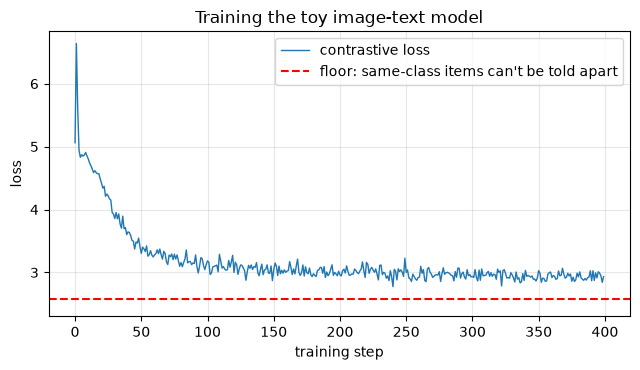

In [8]:
plt.figure(figsize=(6.5, 3.8))
plt.plot(losses, lw=1, label="contrastive loss")
plt.axhline(np.mean(floors), color="red", ls="--", label="floor: same-class items can't be told apart")
plt.ylim(2.3, None); plt.xlabel("training step"); plt.ylabel("loss"); plt.legend(); plt.grid(alpha=0.3)
plt.title("Training the toy image-text model"); plt.tight_layout(); plt.show()

### 3.3 Did it learn a shared space?

Now we repeat the test from Section 2: match each of the 10,000 validation images to the most similar of the 10 descriptions "a photo of a ...". No classifier head was trained for this; we are classifying images purely by comparing them with text.

In [9]:
acc, pred = zero_shot_accuracy(img_enc, txt_enc, X_val, y_val)
print(f"trained: matching 10,000 validation images to 'a photo of a ...', accuracy {acc:.3f}")
for c in range(10):
    m = y_val == c
    print(f"  {NAMES[c]:<11} {(pred[m] == c).float().mean().item():.3f}")

trained: matching 10,000 validation images to 'a photo of a ...', accuracy 0.875
  t-shirt     0.803
  trouser     0.973
  pullover    0.790
  dress       0.903
  coat        0.671
  sandal      0.960
  shirt       0.796
  sneaker     0.947
  bag         0.974
  ankle boot  0.951


The accuracy is now **0.875**, against 0.100 before training. Classes with distinctive shapes are easiest: bags (0.974), trousers (0.973) and sandals (0.960). Coats are hardest (0.671), followed by pullovers (0.790) and shirts (0.796), the same family of similar upper-body garments that troubled the CNN in Note 5.2.

The text side is genuinely flexible, within limits. Because the text encoder averages word embeddings, any combination of words it knows produces a valid description. Let's try different wordings:

In [10]:
for t in TEMPLATES + ["{}", "this is a {}"]:
    try:
        a_, _ = zero_shot_accuracy(img_enc, txt_enc, X_val, y_val, template=t)
        print(f"prompt template {t!r:<32} accuracy {a_:.3f}")
    except KeyError as e:
        print(f"prompt template {t!r:<32} fails: word {e} is not in the vocabulary")

prompt template 'a photo of a {}'                accuracy 0.875


prompt template 'a picture of a {}'              accuracy 0.870


prompt template 'an image showing a {}'          accuracy 0.870


prompt template 'a {} on a plain background'     accuracy 0.868


prompt template '{}'                             accuracy 0.865
prompt template 'this is a {}'                   fails: word 'this' is not in the vocabulary


All four training templates give similar accuracies, from 0.868 to 0.875, and even the bare class name `'{}'`, a description the model never saw on its own during training, scores 0.865. But the prompt "this is a {}" fails completely, because "this" is not one of the 21 words in the vocabulary. Our text encoder can only understand words it was trained on, a limitation we return to in Section 4.

To see the shared space more directly, we average the vectors of all validation images of each class and compare each average with each of the 10 class descriptions. A meaningful shared space should produce a bright diagonal.

average cosine: matching class and description 0.888 | non-matching 0.203
  t-shirt images vs 'a photo of a shirt': 0.71
  coat images vs 'a photo of a shirt': 0.69
  pullover images vs 'a photo of a shirt': 0.68
  coat images vs 'a photo of a pullover': 0.61


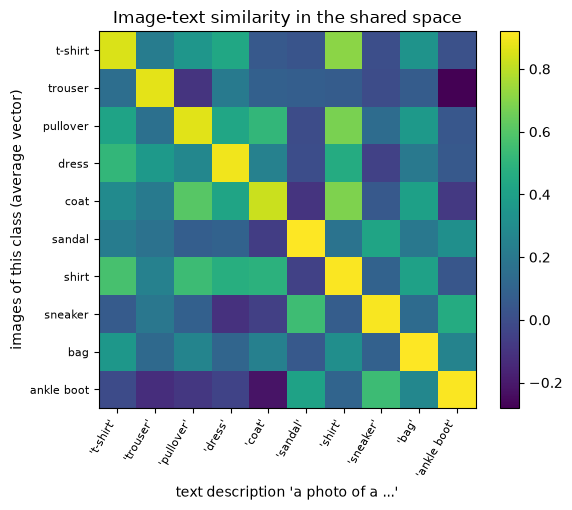

In [11]:
with torch.no_grad():
    T = txt_enc(class_prompts())                      # (10, 32)
    I = img_enc(X_val)                                # (10000, 32)
    M = torch.stack([I[y_val == c].mean(0) for c in range(10)])   # average image vector per class
    M = F.normalize(M, dim=-1)
    sim = M @ T.T                                     # (10 image classes, 10 descriptions)
diag = sim.diag().mean().item(); off = sim[~torch.eye(10, dtype=bool)].mean().item()
print(f"average cosine: matching class and description {diag:.3f} | non-matching {off:.3f}")
pairs = sorted([(sim[i, j].item(), NAMES[i], NAMES[j]) for i in range(10) for j in range(10) if i != j], reverse=True)[:4]
for v, i_, j_ in pairs:
    print(f"  {i_} images vs 'a photo of a {j_}': {v:.2f}")
fig, ax = plt.subplots(figsize=(6.2, 5.2))
im = ax.imshow(sim, cmap="viridis")
ax.set_xticks(range(10)); ax.set_xticklabels([f"'{n}'" for n in NAMES], rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(10)); ax.set_yticklabels(NAMES, fontsize=8)
ax.set_xlabel("text description 'a photo of a ...'"); ax.set_ylabel("images of this class (average vector)")
plt.colorbar(im, fraction=0.046); plt.title("Image-text similarity in the shared space"); plt.tight_layout(); plt.show()

Images and the description of their own class have an average cosine of 0.888; images and other classes' descriptions average 0.203. The brightest off-diagonal cells all involve the hard upper-body classes: T-shirt images against "a photo of a shirt" (0.71), coat images against "shirt" (0.69), pullover images against "shirt" (0.68), and coat images against "pullover" (0.61). The model's confusions in the space are the confusions you would expect.

Finally, a picture of the space itself. We project 1,000 validation images (dots) and the 10 descriptions (stars) together onto two dimensions with PCA. This 2D picture keeps only 50% of the variation in the 32-dimensional vectors, so treat it as an illustration of the numbers above, not a measurement.

the 2D picture keeps 50% of the variation


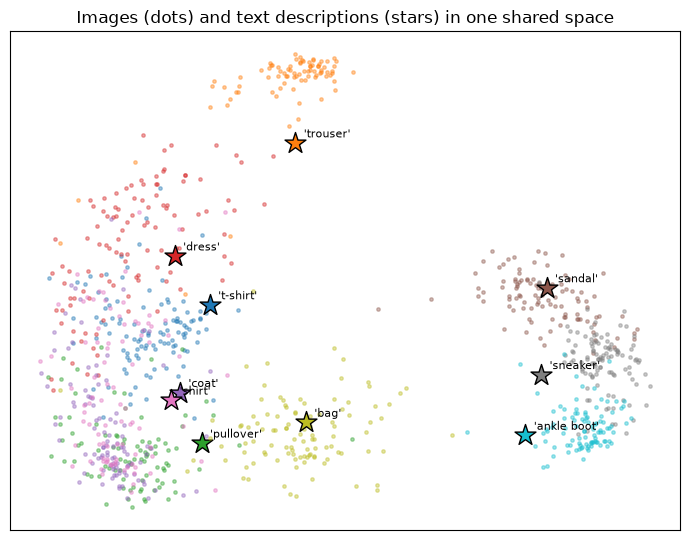

In [12]:
from sklearn.decomposition import PCA
idx = torch.arange(0, 10000, 10)                      # 1,000 validation images
with torch.no_grad():
    pts = torch.cat([img_enc(X_val[idx]), txt_enc(class_prompts())]).numpy()
pca = PCA(2).fit(pts); P = pca.transform(pts)
print(f"the 2D picture keeps {pca.explained_variance_ratio_.sum():.0%} of the variation")
cmap = plt.get_cmap("tab10")
plt.figure(figsize=(7, 5.5))
for c in range(10):
    m = (y_val[idx] == c).numpy()
    plt.scatter(P[:1000][m, 0], P[:1000][m, 1], s=6, color=cmap(c), alpha=0.4)
    plt.scatter(P[1000 + c, 0], P[1000 + c, 1], s=250, marker="*", color=cmap(c), edgecolor="black")
    plt.annotate(f"'{NAMES[c]}'", P[1000 + c], fontsize=8, xytext=(6, 4), textcoords="offset points")
plt.title("Images (dots) and text descriptions (stars) in one shared space")
plt.xticks([]); plt.yticks([]); plt.tight_layout(); plt.show()

The images form clusters by class, and each description sits near its own class's cluster. Two details are worth noticing. The stars lie *near* their clusters rather than in their centres: images and text occupy slightly different regions of the shared space, which is consistent with the matching cosine of 0.888 being high but below 1. And the "coat" and "shirt" stars sit almost on top of each other in the crowded upper-body region, which matches the high coat–shirt similarity of 0.69.

> **Common mistake:** expecting the contrastive loss to go to zero. With false negatives in every batch, it cannot. Judge a contrastive model by what it can *do* (matching accuracy, retrieval quality), not by how low the loss goes.

> **Key terms**
> - **Contrastive learning:** training by pulling matching pairs together and pushing non-matching pairs apart.
> - **Positive / negative pair:** a matching image–caption pair / a non-matching one.
> - **Contrastive loss:** cross-entropy over the image–caption similarity matrix, in both directions, with the matches on the diagonal.
> - **Temperature (scale):** a number that controls how sharply the softmax separates similarity scores.
> - **False negative:** a pair treated as non-matching by the loss even though it is actually a valid match.

> **Check yourself 2.** If we trained with a batch size of 1,024 instead of 128, would the loss floor caused by same-class items go up or down? Why?

## 4. CLIP as an Example of Joint Image–Text Representation Learning

What we have built is a miniature version of **CLIP** (Contrastive Language–Image Pre-training), a model released by OpenAI that showed how powerful this idea becomes at scale. CLIP has exactly the same structure as our toy:

- an **image encoder** (in CLIP, a large CNN or a Vision Transformer, which you will meet in Module 6);
- a **text encoder** (in CLIP, a Transformer that reads the whole sentence, not an average of word vectors);
- **projections** into a shared space, with normalised vectors;
- the **contrastive loss** over large batches of image–caption pairs, with a learned temperature.

The big difference is the data. Our toy learned from 40 template captions about 10 kinds of clothing. CLIP learned from an enormous collection of real images paired with the text that appeared next to them on the internet: captions, titles, descriptions. That variety is what gives CLIP its most famous ability, **zero-shot classification**: classifying images into categories it was never explicitly trained on, simply by writing a description of each category.

> 🖼 *IMAGE 5.5.3 — How CLIP Is Trained and Used.* Two panels on a white background. Left panel titled "Training": a column of four varied photo thumbnails (a dog on a beach, a bowl of noodles, a city skyline, a guitar) flowing into a blue box "image encoder", and a column of four matching caption snippets ("my dog loves the beach", "homemade ramen", "skyline at dusk", "vintage guitar for sale") flowing into a purple box "text encoder". Both boxes feed a 4×4 grid with a bright green diagonal labelled "contrastive loss". Right panel titled "Zero-shot classification": a new photo of a cat flows into the image encoder; a list of written labels "a photo of a dog", "a photo of a cat", "a photo of a car" flows into the text encoder; arrows lead to three similarity bars, with the "cat" bar tallest and highlighted. Takeaway: CLIP learns a shared space from image–text pairs, then classifies new images by comparing them with text descriptions.

### 4.1 Why our toy cannot do true zero-shot classification

Our model did classify images using text, but only for the 10 classes whose captions it was trained on. Is that really "zero-shot"? Let's test it properly. We train a fresh model **without any sneaker images or sneaker captions**, then ask it to recognise sneakers using the description "a photo of a sneaker".

In [13]:
keep = y_train != 7                                   # remove every sneaker image from training
ie_ns, te_ns, _, _ = train_clip(X_train[keep], y_train[keep])
acc_all, pred_ns = zero_shot_accuracy(ie_ns, te_ns, X_val, y_val)
m = y_val == 7
print(f"trained without sneakers: overall accuracy {acc_all:.3f}")
print(f"sneaker images correctly matched to 'a photo of a sneaker': {(pred_ns[m] == 7).float().mean().item():.3f}")
print("what sneakers were matched to instead:",
      {NAMES[c]: int((pred_ns[m] == c).sum()) for c in range(10) if (pred_ns[m] == c).sum() > 0})

trained without sneakers: overall accuracy 0.796
sneaker images correctly matched to 'a photo of a sneaker': 0.000
what sneakers were matched to instead: {'sandal': 721, 'bag': 1, 'ankle boot': 233}


The model trained without sneakers still reaches 0.796 overall on the validation images, but it recognises **none** of the sneakers (0.000). It matches 721 of them to "sandal", 233 to "ankle boot" and 1 to "bag": all visually similar shoes, or nearly. It has learned sensible things about the *images*, since sneakers land near other footwear, but the word "sneaker" never appeared in any training caption, so its embedding is still random. Text it has never learned from carries no meaning.

This is precisely why CLIP's scale matters. CLIP can recognise categories that no one explicitly labelled because, during training, it saw those words in many real captions, alongside many images. Its text encoder has learned what words like "sneaker", "zebra" or "lighthouse" refer to. Zero-shot classification is not magic: it is reuse of what was learned from text during training.

> **Check yourself 3.** Our model, trained without sneakers, matched sneaker images mostly to "sandal" and "ankle boot". What does that tell you about what its *image* encoder learned, even without sneakers in training?

## 5. Applications: Image Search, Text-to-Image Retrieval, and Multimodal AI

A shared image–text space is useful far beyond classification. Because images and text are now comparable, we can **search** in either direction.

### 5.1 Text-to-image search

To search a collection of images with a sentence, embed every image once and store the vectors. To answer a query, embed the text and rank all the stored images by cosine similarity. Here are the top 8 validation images for three queries, with the cosine similarity above each one:

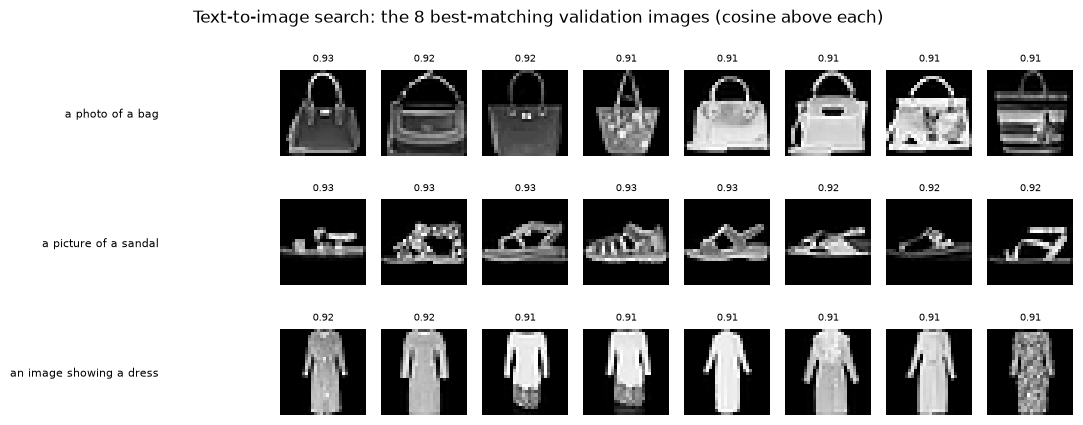

In [14]:
with torch.no_grad():
    I_val = img_enc(X_val)                                # embed every validation image once: (10000, 32)
def search(query, k=8):
    with torch.no_grad():
        scores = I_val @ txt_enc([query])[0]              # one score per validation image
    top = scores.topk(k).indices
    return top, scores[top]

fig, axes = plt.subplots(3, 8, figsize=(11, 4.4))
for row, q in enumerate(["a photo of a bag", "a picture of a sandal", "an image showing a dress"]):
    top, sc = search(q)
    for j, (i, s_) in enumerate(zip(top, sc)):
        axes[row, j].imshow(X_val[i, 0], cmap="gray"); axes[row, j].axis("off")
        axes[row, j].set_title(f"{s_:.2f}", fontsize=7)
    axes[row, 0].text(-40, 14, q, fontsize=8, ha="right", va="center")
plt.suptitle("Text-to-image search: the 8 best-matching validation images (cosine above each)")
plt.tight_layout(); plt.show()

Every result in all three rows is from the requested class, with cosine similarities between 0.91 and 0.93. Let's measure this more broadly: for each class, we search with "a photo of a ..." and check what fraction of the top 100 results really belong to that class. This fraction is called **precision at 100**.

In [15]:
precision = []
for c in range(10):
    top, _ = search(f"a photo of a {NAMES[c]}", k=100)
    precision.append((y_val[top] == c).float().mean().item())
    print(f"'a photo of a {NAMES[c]}': {precision[-1]:.2f} of the top 100 results really are {NAMES[c]} images")
print(f"average precision of the top 100: {np.mean(precision):.3f}")

'a photo of a t-shirt': 0.95 of the top 100 results really are t-shirt images
'a photo of a trouser': 1.00 of the top 100 results really are trouser images
'a photo of a pullover': 0.98 of the top 100 results really are pullover images
'a photo of a dress': 0.95 of the top 100 results really are dress images
'a photo of a coat': 0.95 of the top 100 results really are coat images
'a photo of a sandal': 1.00 of the top 100 results really are sandal images
'a photo of a shirt': 0.99 of the top 100 results really are shirt images
'a photo of a sneaker': 0.95 of the top 100 results really are sneaker images
'a photo of a bag': 0.99 of the top 100 results really are bag images
'a photo of a ankle boot': 1.00 of the top 100 results really are ankle boot images
average precision of the top 100: 0.976


Precision at 100 is 1.00 for trousers, sandals and ankle boots, and at least 0.95 for every class, averaging 0.976. Even coats, the hardest class to classify, reach 0.95: the very *best* matches for a query are much more reliable than the average match.

Notice something about this search: no image was ever tagged with keywords. The ranking came entirely from the shared space. That is how modern photo libraries let you search your own pictures by typing what you remember.

### 5.2 Other applications

The same shared space powers several other kinds of system:

- **Image-to-text retrieval:** find the captions, products or documents that best match an image (the reverse direction of the search above).
- **Zero-shot classification:** as in Section 4, classify images into categories described in words, without training a new classifier.
- **Duplicate and similarity search:** find images similar to a given image by comparing image vectors directly.
- **Guiding image generation:** some text-to-image generators use a CLIP-style shared space to check how well a generated image matches the prompt.
- **Multimodal assistants:** models that answer questions about images often begin with an image encoder trained in a shared image–text space, whose vectors are then passed to a language model.

You will load a real pretrained CLIP model and use it for zero-shot classification and search in Module 7.

> **Key terms**
> - **Retrieval:** finding the items in a collection that best match a query.
> - **Precision at k:** the fraction of the top k results that are correct.
> - **Zero-shot classification:** classifying into categories using descriptions only, without training on labelled examples of those categories.

> **Check yourself 4.** In the search above, we embedded all 10,000 validation images once and reused their vectors for every query. Why is this important for a real search system with millions of images?

## Putting It All Together

Images and text are different **modalities**, and separately trained encoders produce vectors that cannot be compared. Matching images to class descriptions with untrained encoders scored 0.100, pure chance.

To build a **shared space**, we gave each modality its own encoder (a CNN for images, averaged word embeddings for text) followed by a **projection** into the same 32-dimensional space, with normalised vectors. We trained both encoders together with **contrastive learning**: compute the similarity of every image with every caption in a batch, and use cross-entropy in both directions to make the diagonal (the true pairs) win. The loss fell from about ln(128) = 4.852 towards a floor of 2.584 set by **false negatives**, same-class items the loss cannot tell apart.

The resulting space works: matching 10,000 validation images to text descriptions reached 0.875, matching classes had cosine 0.888 against 0.203 for the rest, and text-to-image search achieved an average precision at 100 of 0.976. Its limits are just as instructive: it failed on words outside its 21-word vocabulary, and when sneakers were left out of training it recognised none of them (0.000).

**CLIP** is the same recipe, with Transformer encoders and a vast collection of real image–caption pairs from the internet. That scale is what turns "matching known classes with text" into genuine zero-shot classification and open-ended search.

> 🖼 *IMAGE 5.5.4 — Shared-Space Recipe.* A symmetric diagram on a white background. On the left, a stack of greyscale clothing thumbnails flows into a blue trapezoid "image encoder (CNN)", then a small blue box "projection → 32 numbers, length 1". On the right, a stack of captions flows into a purple trapezoid "text encoder (embeddings)", then a small purple box "projection → 32 numbers, length 1". Both projections point into a central circle labelled "shared space", drawn with ten small coloured clusters, each with a few dots (images) and a star (text) side by side. Below the circle, a small 4×4 matrix with a green diagonal labelled "contrastive loss: pull matches together, push others apart". Beneath everything, three small output icons with arrows from the circle: a magnifying glass "search", a tag "classify by description", and a pair of linked images "find similar". Takeaway: two encoders plus projections plus contrastive training produce one space where images and text can be compared.

## Summary

- A **modality** is a type of data. Separate encoders for separate modalities produce incompatible vectors.
- A **shared representation space** is created by giving each encoder a **projection** to vectors of the same length, normalised so that dot product equals cosine similarity.
- **Contrastive learning** trains both encoders together: for a batch of pairs, cross-entropy over the similarity matrix in both directions pulls true pairs together and pushes others apart. A **temperature** (scale) controls how sharp the softmax is.
- Same-class items in a batch act as **false negatives**, so the contrastive loss has a floor above zero (2.584 here). Judge the model by what it can do.
- Our toy model matched validation images to text descriptions with 0.875 accuracy and searched images by text with average precision at 100 of 0.976.
- It could not understand words it was never trained on, and could not recognise sneakers when they were left out (0.000).
- **CLIP** uses the same recipe at enormous scale with Transformer encoders, which enables zero-shot classification and open-ended image search. You will use it in Module 7.

## Glossary

| Term | Meaning |
|---|---|
| Modality | A type of data, such as images, text or audio. |
| Multimodal | Involving more than one modality. |
| Shared representation space | One vector space in which different modalities can be compared directly. |
| Projection | A layer mapping an encoder's output into the shared space. |
| Normalise | Scale a vector to length 1. |
| Template | A sentence pattern with a slot for a class name, such as "a photo of a {}". |
| Contrastive learning | Learning by pulling matching pairs together and pushing non-matching pairs apart. |
| Positive / negative pair | A matching / non-matching pair. |
| Contrastive loss | Cross-entropy over a batch's image–text similarity matrix, in both directions. |
| Temperature (scale) | A factor controlling how sharply softmax separates scores. |
| False negative | A pair treated as non-matching even though it is a valid match. |
| CLIP | Contrastive Language–Image Pre-training: a large model that learns a shared image–text space. |
| Zero-shot classification | Classifying into categories described in words, without labelled training examples of them. |
| Retrieval | Finding the best-matching items in a collection for a query. |
| Precision at k | The fraction of the top k retrieved results that are correct. |

## Answers to Check Yourself

**1.** Comparing an image with a caption means computing a dot product (or cosine similarity) between their vectors, which is only defined for vectors of the same length. The projections are what translate both modalities into the same "coordinates".

**2.** It would go up. With 1,024 items and 10 classes, each batch would contain about ten times as many same-class items, so each image would have more indistinguishable "correct" captions to spread its probability over. The floor is roughly the logarithm of that number, so a larger batch means a higher floor. (Real systems like CLIP use very diverse captions, so true duplicates in a batch are rare, and large batches mainly help by providing more, and harder, negatives.)

**3.** Its image encoder learned general visual features of footwear, such as a low, wide outline with a sole, even without seeing sneakers. Sneaker images landed near sandal and ankle-boot images in the shared space. What was missing was the text side: the word "sneaker" had no learned meaning to match them to.

**4.** Embedding an image requires running the image encoder, which is expensive. If we re-embedded millions of images for every query, each search would take far too long. By embedding the collection once and storing the vectors, each new query costs only one text embedding plus fast dot products, which can be done for millions of stored vectors very quickly.